# Block-overlay walking friction prototype

## What changed?
Every cached OSM walking edge remains in the map. We estimate walking conditions from the **three existing census-block overlays**, rather than requiring all direct edge observations.

1. Intersect each walking edge with census blocks.
2. For each factor, weight available block summaries by the length of the edge within those blocks.
3. If a factor has no valid intersecting block, use the nearest valid block within **250 meters**, marking the transfer and recording its source.
4. Require all three estimated factors for the block-proxy cost. Do not fabricate a road or trail to fill a geometric gap.

$$w_e=\frac{L_e}{1.2}\left[1+\frac{(1-\widehat{C}_e)+\widehat{Q}_e+\widehat{H}_e}{3}\right]$$

Hats indicate **block-context proxies**, not direct path measurements. The equal weights are assumptions. AI supplies the existing tree predictions; this overlay step is GIS processing.

**Coverage:** 93,450 / 93,452 edges have a three-factor proxy weight. Two remain unsupported. 874 edges use at least one nearby-block transfer; 2,664 have incomplete block overlap for at least one factor. These categories can overlap.

**Routes:** 328 reachable residential-to-POI pairs, retaining no residential-to-residential or POI-to-POI recommendation edges. Only four provisional origins are included, not all residences.


edge_count                          93452
weighted_edges                      93450
unknown_edges                           2
nearby_block_used_edges               874
partial_or_missing_overlap_edges     2664
Name: Edges, dtype: int64

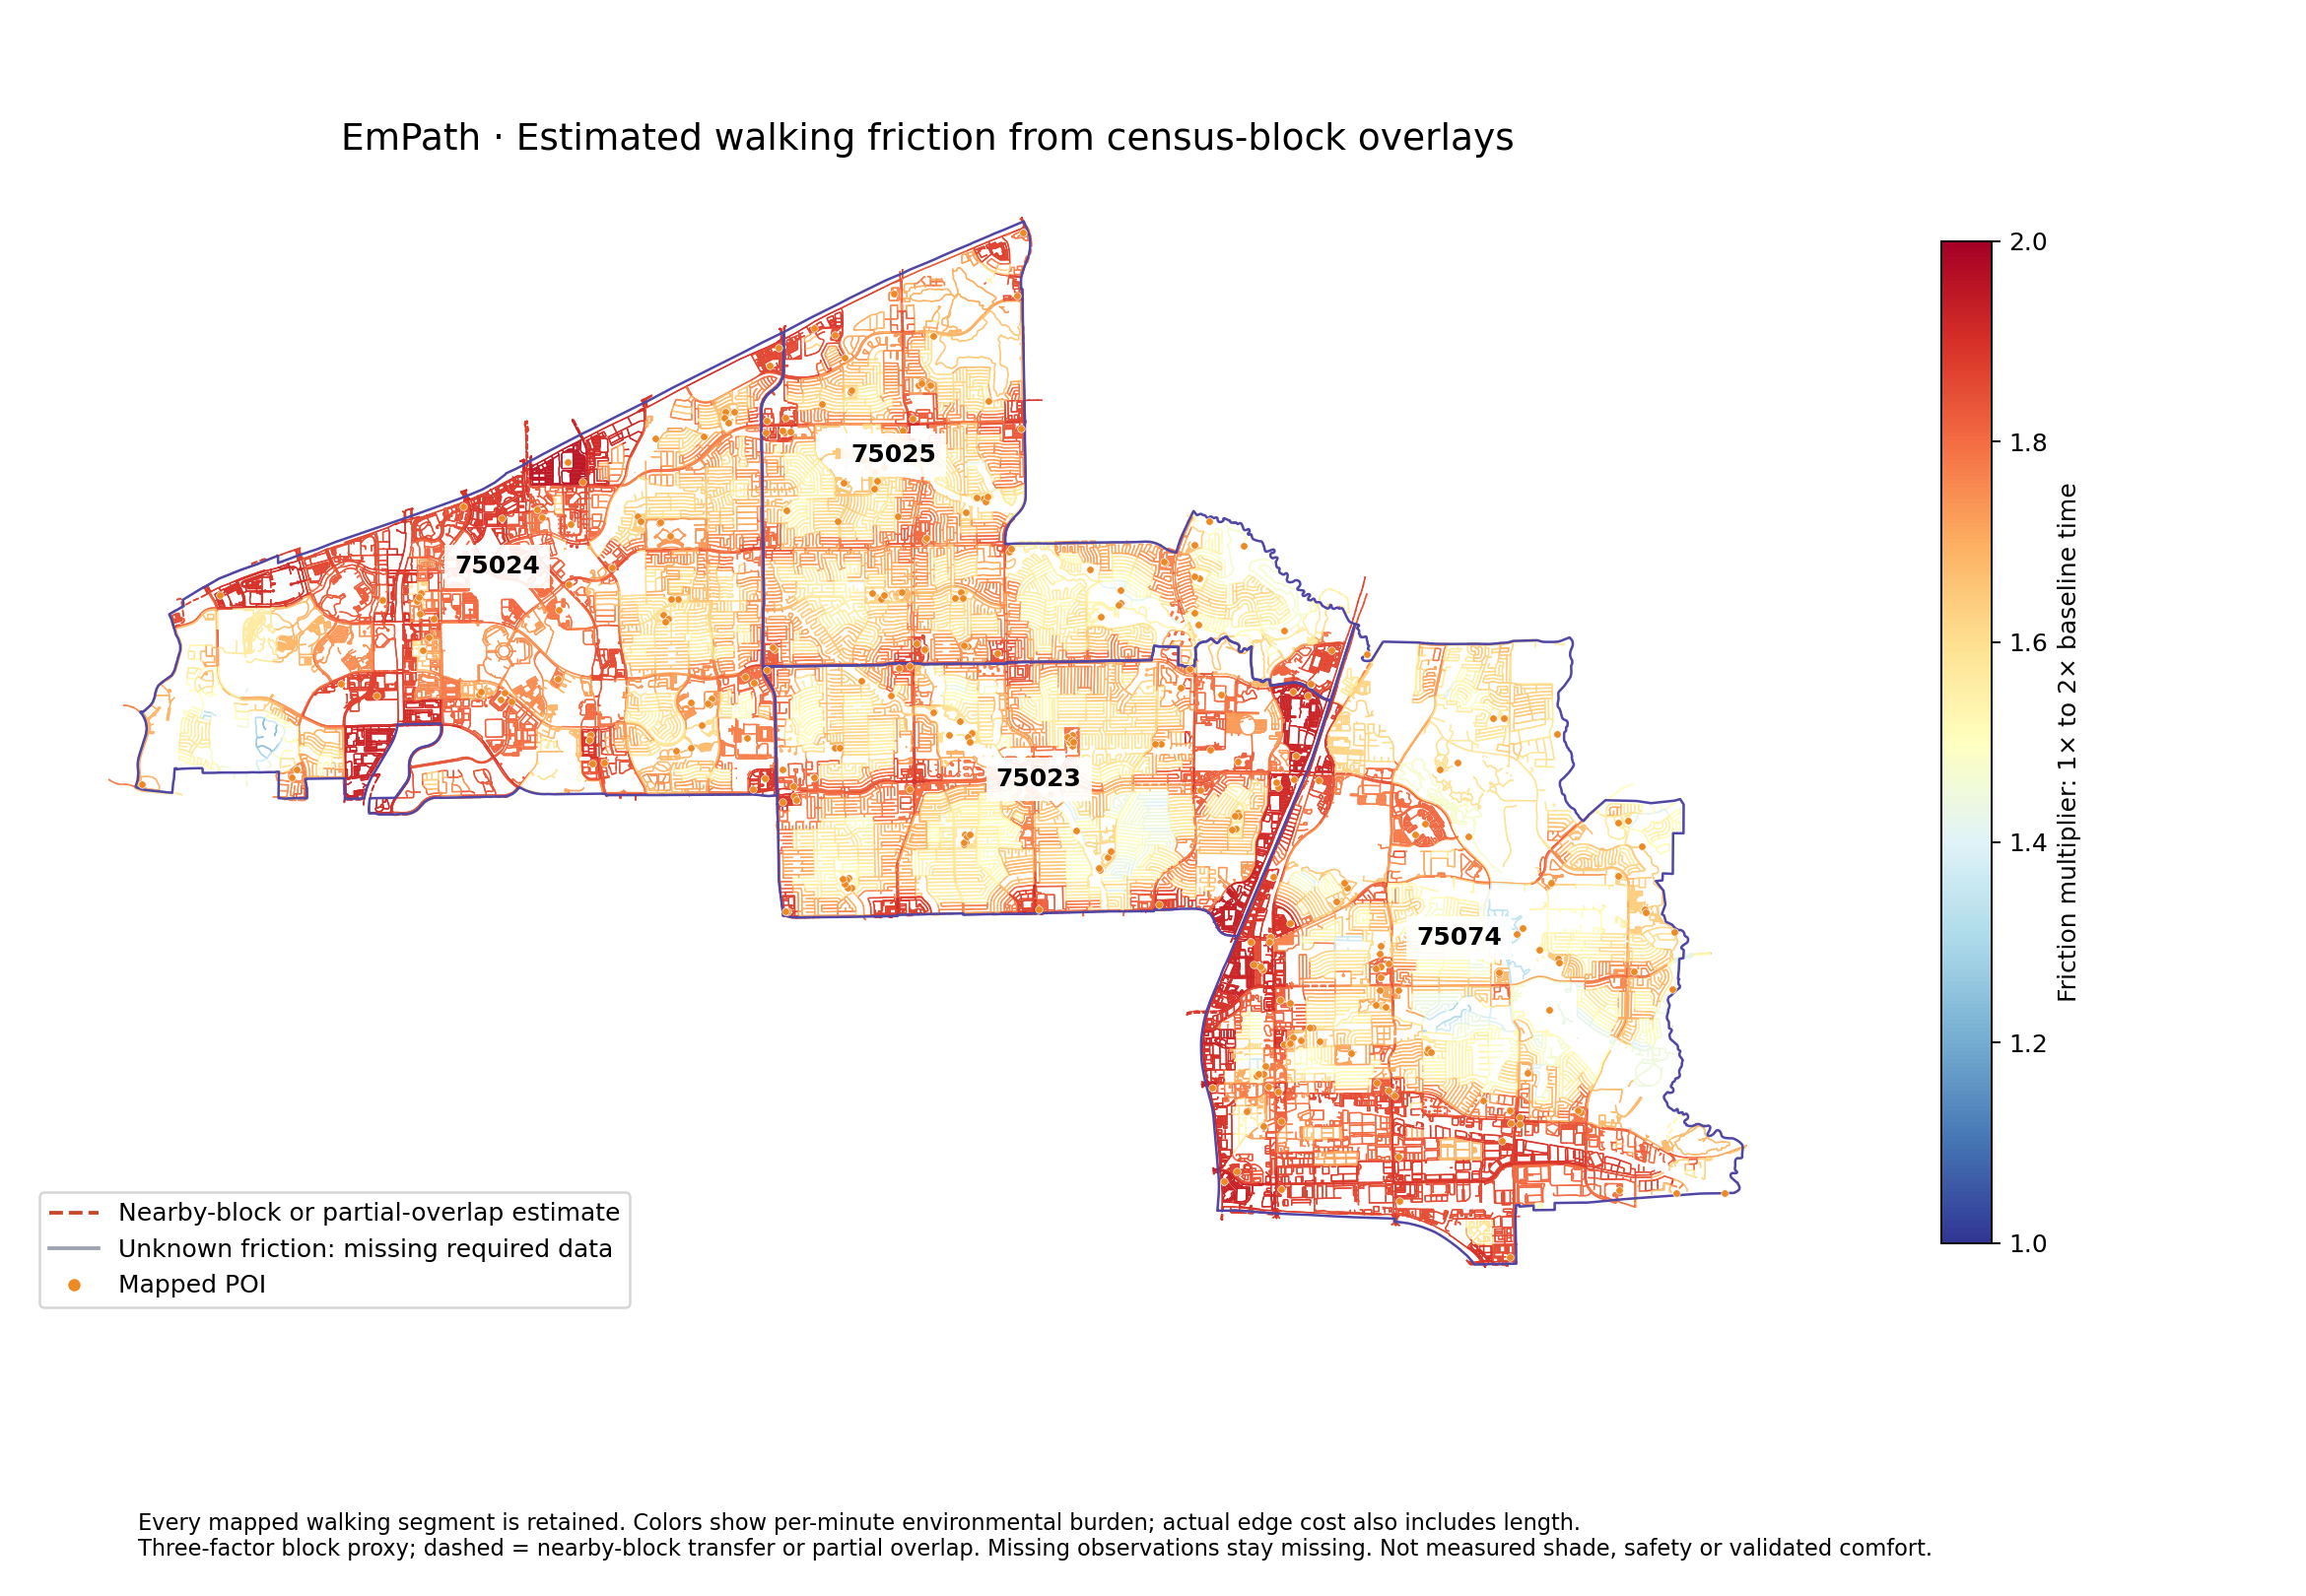

Open the current map in your browser: /Users/nalinikantheti/Documents/ChatGPT/EmPath/output/weighted_walking_network/block_proxy_weighted_network.html


/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/weighted_walking_network/block_proxy_weighted_network.html

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, FileLink
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
REBUILD = False  # change to True after inputs change
if REBUILD:
    from block_proxy_friction import run as make_proxies
    from build_residential_poi_graph import run as make_graphs
    from visualize_weighted_walking_network import run as make_maps
    make_proxies()
    make_graphs()
    make_maps()
report = json.loads((ROOT/'output/step3_friction/block_proxy_method.json').read_text())
display(pd.Series({k:report[k] for k in ['edge_count','weighted_edges','unknown_edges','nearby_block_used_edges','partial_or_missing_overlap_edges']},name='Edges'))
display(Image(filename=str(ROOT/'output/weighted_walking_network/block_proxy_weighted_network.png')))
map_path=ROOT/'output/weighted_walking_network/block_proxy_weighted_network.html'
print('Open the current map in your browser:',map_path)
display(FileLink(str(map_path)))


## Inspect the actual sources

- Default map mode: **Three block overlays · proxy estimate**.
- Click paths to compare original edge inputs with block-proxy inputs and factor-specific provenance.
- Dashed lines: nearby-block transfer or partial block overlap. All block-mode costs are estimates, even solid lines.
- Toggle **Census blocks · source environmental summaries** to inspect the input polygons.
- Toggle **Municipal trail reference · not integrated into routing** to identify possible OSM geometry gaps. Reference trails do not automatically become routable.
- Other scoring modes remain selectable for comparison.

## Files
- `output/step3_friction/block_proxy_edge_costs.csv`: edge-level proxy inputs and per-factor source, nearest-block distance/ID, overlap fraction and cost.
- `output/step3_friction/block_proxy_method.json`: assumptions and coverage checks.
- `output/residential_poi_graph/block_context_proxy_activity_graph.graphml`: weighted origin-to-POI graph.
- `output/residential_poi_graph/origin_poi_routes.gpkg`: exact routes; filter objective `block_context_proxy`.

A blank area without any source walking line is a geometry/coverage issue; estimating canopy, traffic or heat does not create a legal path. Block summaries smooth local variation and may miss trail-level advantages. Inspect actual trails and access before making accessibility claims.
